# Day 27 / 100 — EnergyPeak Predictor

**Industrial energy forecasting, peak-demand identification, and cross-domain time-series experiments.**

- **Experiment A (primary):** UCI Steel Industry Energy Consumption — 15-minute industrial electricity usage.
- **Experiment B (secondary):** UCI ElectricityLoadDiagrams20112014 — 370 consumer series, 15-minute intervals. Per-series forecasts, not concatenated into the steel dataset.
- **Experiment C (auxiliary):** UCI Appliances Energy Prediction — residential energy, 10-minute intervals; different domain.

**Scientific contract:** one-step-ahead forecasts from *past observed values only*; chronological 60% train / 20% validation / 20% untouched test; choose champion using validation MAE; peak cutoff learned solely from training target values; actual held-out metrics only. Outputs are research estimates, **not** real-time grid control recommendations. All timestamps and feature availability must be audited.

> **Input:** `/kaggle/input/datasets/loliwibu/energypeak-predictor-dataset`. The notebook discovers file paths recursively to accommodate Kaggle mount changes. If Kaggle has a different path, change `INPUT_ROOT` only.

## 00 — Environment, configuration, reproducibility

In [1]:
from __future__ import annotations
import os, sys, json, time, math, hashlib, zipfile, warnings, platform
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, precision_recall_fscore_support, confusion_matrix
import joblib

SEED = 42
np.random.seed(SEED)
INPUT_ROOT = Path('/kaggle/input/datasets/loliwibu/energypeak-predictor-dataset')
OUT = Path('/kaggle/working/energypeak_day27')
for sub in ('reports','plots','models','features','examples'):
    (OUT/sub).mkdir(parents=True, exist_ok=True)
REPORT, PLOTS, MODELS, FEATURES = (OUT/sub for sub in ('reports','plots','models','features'))
CFG = {
 'train_fraction': .60, 'validation_fraction': .20, 'test_fraction': .20,
 'lags': [1,2,3,4,8,12,24,48,96], 'rolling_windows': [4,12,48,96],
 'peak_quantile': .90, 'min_usable_rows': 500,
 'electricity_max_series': 12, # representative non-empty series; change to 370 for full experiment
 'electricity_min_nonzero_fraction': .05,
 'rf_estimators': 160,
 'zip_include_features': False,
}
print('Python:',sys.version.split()[0], 'Pandas:',pd.__version__)
print('Input directory present:',INPUT_ROOT.is_dir())
if not INPUT_ROOT.is_dir():
    print('Kaggle mounts:', [str(p) for p in Path('/kaggle/input').rglob('*') if p.is_dir()][:30])
    raise FileNotFoundError('Attach the Day 27 Kaggle dataset or update INPUT_ROOT')
(REPORT/'run_config.json').write_text(json.dumps({'input_root':str(INPUT_ROOT),'seed':SEED,'configuration':CFG,'python':sys.version},indent=2),encoding='utf-8')

Python: 3.13.15 Pandas: 2.3.3
Input directory present: True


642

## 01 — Inventory, original sources, and attribution

In [2]:
files = sorted([p for p in INPUT_ROOT.rglob('*') if p.is_file()])
inv = pd.DataFrame([{'path':p.relative_to(INPUT_ROOT).as_posix(),'size_MiB':round(p.stat().st_size/1024**2,3),'suffix':p.suffix.lower()} for p in files])
display(inv)
inv.to_csv(REPORT/'input_inventory.csv',index=False)
provenance=pd.DataFrame([
 {'dataset':'Steel Industry Energy Consumption','source':'https://archive.ics.uci.edu/dataset/851/steel+industry+energy+consumption','role':'primary industrial forecasting','target':'Usage_kWh','interval':'15min','scope':'one industrial facility'},
 {'dataset':'ElectricityLoadDiagrams20112014','source':'https://archive.ics.uci.edu/dataset/321/electricityloaddiagrams20112014','role':'secondary multi-consumer forecasting','target':'MT_###','interval':'15min','scope':'individual client streams'},
 {'dataset':'Appliances Energy Prediction','source':'https://archive.ics.uci.edu/dataset/374/appliances+energy+prediction','role':'auxiliary cross-domain forecasting','target':'Appliances','interval':'10min','scope':'residential building'},
])
display(provenance)
provenance.to_csv(REPORT/'source_provenance.csv',index=False)

def locate(filename):
    matches=[p for p in files if p.name.lower()==filename.lower()]
    if len(matches)!=1:
        raise FileNotFoundError(f'Expected one {filename}, got {len(matches)}. Available files: {inv.path.tolist()[:30]}')
    return matches[0]
STEEL_PATH=locate('Steel_industry_data.csv')
ELEC_PATH=locate('LD2011_2014.txt')
APP_PATH=locate('energydata_complete.csv')
print('Steel:', STEEL_PATH, '\nElectricity:',ELEC_PATH,'\nAppliances:',APP_PATH)

,path,size_MiB,suffix
0,appliances-energy/energydata_complete.csv,11.424,.csv
1,electricity-load/LD2011_2014.txt,678.061,.txt
2,steel-industry/Steel_industry_data.csv,2.605,.csv


,dataset,source,role,target,interval,scope
0,Steel Industry Energy Consumption,https://archive.ics.uci.edu/dataset/851/steel+...,primary industrial forecasting,Usage_kWh,15min,one industrial facility
1,ElectricityLoadDiagrams20112014,https://archive.ics.uci.edu/dataset/321/electr...,secondary multi-consumer forecasting,MT_###,15min,individual client streams
2,Appliances Energy Prediction,https://archive.ics.uci.edu/dataset/374/applia...,auxiliary cross-domain forecasting,Appliances,10min,residential building


Steel: /kaggle/input/datasets/loliwibu/energypeak-predictor-dataset/steel-industry/Steel_industry_data.csv 
Electricity: /kaggle/input/datasets/loliwibu/energypeak-predictor-dataset/electricity-load/LD2011_2014.txt 
Appliances: /kaggle/input/datasets/loliwibu/energypeak-predictor-dataset/appliances-energy/energydata_complete.csv


## 02 — Audited parsing and data-quality report

In [3]:
def parse_frame(kind):
    if kind == 'steel':
        frame=pd.read_csv(STEEL_PATH)
        frame['timestamp']=pd.to_datetime(frame['date'],format='%d/%m/%Y %H:%M',errors='coerce')
        frame['value']=pd.to_numeric(frame['Usage_kWh'],errors='coerce')
        return frame[['timestamp','value']].copy()
    if kind == 'appliances':
        frame=pd.read_csv(APP_PATH)
        frame['timestamp']=pd.to_datetime(frame['date'],errors='coerce')
        frame['value']=pd.to_numeric(frame['Appliances'],errors='coerce')
        return frame[['timestamp','value']].copy()
    raise ValueError(kind)

def audit_series(frame,name,expected_minutes):
    d=frame[['timestamp','value']].copy()
    nat=int(d.timestamp.isna().sum()); invalid=int(pd.to_numeric(d.value,errors='coerce').isna().sum())
    d=d.dropna(subset=['timestamp','value']).sort_values('timestamp').reset_index(drop=True)
    dup=int(d.timestamp.duplicated().sum())
    if dup:
        print(f'WARNING {name}: {dup} duplicated timestamps. Remove duplicate timestamps (keep first) and report; do not aggregate silently.')
        d=d.drop_duplicates(subset=['timestamp'],keep='first').reset_index(drop=True)
    delta=d.timestamp.diff().dropna()
    deviations=int((delta != pd.Timedelta(minutes=expected_minutes)).sum())
    rec={'dataset':name,'raw_rows':len(frame),'valid_unique_rows':len(d),'invalid_timestamps':nat,'invalid_values':invalid,'duplicate_timestamps':dup,'irregular_intervals':deviations,'time_min':str(d.timestamp.min()),'time_max':str(d.timestamp.max()),'negative_values':int((d.value<0).sum()),'zero_values':int((d.value==0).sum()),'expected_interval_minutes':expected_minutes}
    if len(d)<CFG['min_usable_rows']:raise ValueError(f'{name}: insufficient usable rows {len(d)}')
    if (d.value<0).any():raise ValueError(f'{name}: negative consumption; audit source before modeling')
    return d,rec

steel,steel_audit=audit_series(parse_frame('steel'),'steel',15)
appliances,app_audit=audit_series(parse_frame('appliances'),'appliances',10)
display(pd.DataFrame([steel_audit,app_audit]))
print('No global imputation or resampling performed: irregular interval counts are reported.')

,dataset,raw_rows,valid_unique_rows,invalid_timestamps,invalid_values,duplicate_timestamps,irregular_intervals,time_min,time_max,negative_values,zero_values,expected_interval_minutes
0,steel,35040,35040,0,0,0,0,2018-01-01 00:00:00,2018-12-31 23:45:00,0,1,15
1,appliances,19735,19735,0,0,0,0,2016-01-11 17:00:00,2016-05-27 18:00:00,0,0,10


No global imputation or resampling performed: irregular interval counts are reported.


## 03 — ElectricityLoadDiagrams: semicolon delimiter + decimal-comma audit

In [4]:
# UCI electricity-load file uses a semicolon separator and decimal comma.
# Parsing with default comma delimiter silently turns many client columns into object strings.
with ELEC_PATH.open('r',encoding='utf-8-sig',errors='replace') as f:
    first_line=f.readline()
print('Raw header preview:',first_line[:180].rstrip())
if first_line.count(';') < 300:
    raise ValueError('Expected >=370 semicolon-delimited columns. Inspect the original file format.')
# Full 678 MiB file: 370 clients x ~140k rows. Float32 significantly reduces memory use.
electricity_raw=pd.read_csv(ELEC_PATH,sep=';',decimal=',',encoding='utf-8-sig',low_memory=False)
electricity_raw=electricity_raw.rename(columns={electricity_raw.columns[0]:'timestamp'})
electricity_raw['timestamp']=pd.to_datetime(electricity_raw['timestamp'],errors='coerce')
customer_cols=[c for c in electricity_raw.columns if c.startswith('MT_')]
print('Electricity shape:',electricity_raw.shape,'client columns:',len(customer_cols))
if len(customer_cols)!=370:raise ValueError('Expected 370 electricity clients')
if electricity_raw.timestamp.isna().any():raise ValueError('Unparseable electricity timestamps')
if electricity_raw.timestamp.duplicated().any():raise ValueError('Duplicate electricity timestamps')
if not electricity_raw.timestamp.is_monotonic_increasing:
    electricity_raw=electricity_raw.sort_values('timestamp').reset_index(drop=True)
non_numeric=[]
for col in customer_cols:
    electricity_raw[col]=pd.to_numeric(electricity_raw[col],errors='coerce').astype('float32')
    if electricity_raw[col].notna().sum()==0: non_numeric.append(col)
    if (electricity_raw[col].dropna()<0).any():raise ValueError(f'Negative readings in {col}')
if non_numeric: print('Entirely non-numeric client streams:',non_numeric)
nonzero=(electricity_raw[customer_cols].fillna(0)>0).mean(axis=0)
availability=electricity_raw[customer_cols].notna().mean(axis=0)
client_audit=pd.DataFrame({'client':customer_cols,'valid_fraction':availability.values,'nonzero_fraction':nonzero.values,'mean_level':electricity_raw[customer_cols].mean().values})
client_audit.to_csv(REPORT/'electricity_client_inventory.csv',index=False)
client_audit=client_audit.sort_values(['valid_fraction','nonzero_fraction','client'],ascending=[False,False,True])
selected_clients=client_audit.loc[(client_audit.nonzero_fraction>=CFG['electricity_min_nonzero_fraction'])&(client_audit.valid_fraction>=.90)].head(CFG['electricity_max_series']).client.tolist()
if not selected_clients:raise RuntimeError('No suitable electricity clients; review audit before selection')
print('Selected clients:',selected_clients)
print('Electricity calendar:',electricity_raw.timestamp.min(),electricity_raw.timestamp.max())
print('Electricity duplicate rows:',electricity_raw.timestamp.duplicated().sum())
print('Electricity 15-min gaps:',int((electricity_raw.timestamp.diff().dropna()!=pd.Timedelta(minutes=15)).sum()))
print('Client-selection rule is descriptive completeness, NOT predictive test performance.')
del nonzero,availability

Raw header preview: "";"MT_001";"MT_002";"MT_003";"MT_004";"MT_005";"MT_006";"MT_007";"MT_008";"MT_009";"MT_010";"MT_011";"MT_012";"MT_013";"MT_014";"MT_015";"MT_016";"MT_017";"MT_018";"MT_019";"MT_02
Electricity shape: (140256, 371) client columns: 370
Selected clients: ['MT_156', 'MT_158', 'MT_159', 'MT_166', 'MT_168', 'MT_169', 'MT_171', 'MT_172', 'MT_176', 'MT_180', 'MT_182', 'MT_183']
Electricity calendar: 2011-01-01 00:15:00 2015-01-01 00:00:00
Electricity duplicate rows: 0
Electricity 15-min gaps: 0
Client-selection rule is descriptive completeness, NOT predictive test performance.


## 04 — Forecasting protocol and leakage-safe feature construction

In [5]:
def build_lag_features(series,expected_minutes):
    # All input signals use readings at t-1 or earlier. No contemporaneous observed value.
    df=series[['timestamp','value']].sort_values('timestamp').reset_index(drop=True).copy()
    df['valid_target']=df['value'].notna() & (df['value']>=0)
    # Use time-grid continuity per row; missing grid intervals invalidate windows instead of shifting time silently.
    previous=df['timestamp'].shift(1)
    contiguous=df['timestamp'].diff().eq(pd.Timedelta(minutes=expected_minutes))
    # Segments reset whenever timestamps are not exactly one interval apart.
    segment=(~contiguous).cumsum()
    parts=[]
    for k in CFG['lags']:
        v=df.groupby(segment,sort=False)['value'].shift(k)
        parts.append(v.rename(f'lag_{k}'))
    shifted=df.groupby(segment,sort=False)['value'].shift(1)
    for w in CFG['rolling_windows']:
        rolling=shifted.groupby(segment,sort=False).transform(lambda s:s.rolling(w,min_periods=w).mean())
        parts.append(rolling.rename(f'rolling_mean_{w}'))
        rolling_std=shifted.groupby(segment,sort=False).transform(lambda s:s.rolling(w,min_periods=w).std())
        parts.append(rolling_std.rename(f'rolling_std_{w}'))
    # Calendar features known before target time; safe for one-step prediction.
    t=df.timestamp
    mins=t.dt.hour*60+t.dt.minute
    parts += [pd.Series(np.sin(2*np.pi*mins/1440),name='minute_sin'),pd.Series(np.cos(2*np.pi*mins/1440),name='minute_cos'),pd.Series(np.sin(2*np.pi*t.dt.dayofweek/7),name='weekday_sin'),pd.Series(np.cos(2*np.pi*t.dt.dayofweek/7),name='weekday_cos')]
    feature=pd.concat([df[['timestamp','value']],*parts],axis=1)
    feature=feature.replace([np.inf,-np.inf],np.nan)
    feature=feature.dropna().reset_index(drop=True)
    feature=feature.rename(columns={'value':'y'})
    if len(feature)<CFG['min_usable_rows']:raise RuntimeError(f'Only {len(feature)} rows survive lag construction; missingness too high')
    return feature

def split_chronological(df):
    n=len(df);cut1=int(n*CFG['train_fraction']);cut2=int(n*(CFG['train_fraction']+CFG['validation_fraction']))
    tr=df.iloc[:cut1].copy();va=df.iloc[cut1:cut2].copy();te=df.iloc[cut2:].copy()
    if min(len(tr),len(va),len(te))<50:raise ValueError('Insufficient split size')
    assert tr.timestamp.max()<va.timestamp.min()<te.timestamp.min()
    return tr,va,te

def smape(y,yhat):
    y=np.asarray(y,dtype=float);p=np.asarray(yhat,dtype=float)
    return float(200*np.mean(np.abs(y-p)/np.maximum(np.abs(y)+np.abs(p),1e-8)))

def metrics(y,yhat):
    return {'MAE':float(mean_absolute_error(y,yhat)), 'RMSE':float(np.sqrt(mean_squared_error(y,yhat))), 'sMAPE_percent':smape(y,yhat)}

def peak_metrics(y,yhat,threshold):
    actual=(np.asarray(y)>=threshold).astype(int);pred=(np.asarray(yhat)>=threshold).astype(int)
    prec,rec,f1,_=precision_recall_fscore_support(actual,pred,average='binary',zero_division=0)
    return {'peak_threshold_train_p90':float(threshold),'actual_peaks':int(actual.sum()),'predicted_peaks':int(pred.sum()),'peak_precision':float(prec),'peak_recall':float(rec),'peak_f1':float(f1),'peak_confusion_matrix':confusion_matrix(actual,pred,labels=[0,1]).tolist()}

FEATURE_EXCLUSION={'timestamp','y'}
print('Protocol loaded: time-ordered split, train-derived peak cutoffs, no test-based selection.')

Protocol loaded: time-ordered split, train-derived peak cutoffs, no test-based selection.


## 05 — Candidate models and selection rules

In [6]:
from sklearn.base import clone

def candidates():
    return {
      'seasonal_naive_lag96':None,
      'random_forest_160':RandomForestRegressor(n_estimators=CFG['rf_estimators'],min_samples_leaf=3,max_features=.75,n_jobs=-1,random_state=SEED),
      'hist_gradient_boosting':HistGradientBoostingRegressor(max_iter=170,learning_rate=.06,max_leaf_nodes=23,l2_regularization=2.0,random_state=SEED)
    }

def fit_and_predict(name, estimator, Xtr,ytr,Xpred):
    if name=='seasonal_naive_lag96':
        return None,np.asarray(Xpred['lag_96'],dtype=float)
    pipe=Pipeline([('imputer',SimpleImputer(strategy='median')),('estimator',clone(estimator))])
    pipe.fit(Xtr,ytr)
    return pipe,pipe.predict(Xpred)

def run_experiment(name, data, interval_minutes, export_features=False):
    print('\n'+'='*70,'\n',name,'\n'+'='*70)
    df=build_lag_features(data,interval_minutes)
    train,val,test=split_chronological(df)
    columns=[c for c in df if c not in FEATURE_EXCLUSION]
    Xtr,ytr=train[columns],train.y
    Xva,yva=val[columns],val.y
    Xte,yte=test[columns],test.y
    ledger=[]
    candidate_set=candidates()
    for candidate,model in candidate_set.items():
        _,pv=fit_and_predict(candidate,model,Xtr,ytr,Xva)
        record={'dataset':name,'candidate':candidate,**metrics(yva,pv),'selection_split':'validation_only'}
        ledger.append(record)
    validation=pd.DataFrame(ledger).sort_values(['MAE','candidate']).reset_index(drop=True)
    champion=validation.iloc[0]['candidate']
    # Following model selection, refit on TRAIN+VALIDATION (no TEST until now).
    trainval=pd.concat([train,val],ignore_index=True)
    fitted,pred=fit_and_predict(champion,candidate_set[champion],trainval[columns],trainval.y,Xte)
    # Threshold is fit from ORIGINAL TRAIN only, not train+validation or test.
    peak_cutoff=float(train.y.quantile(CFG['peak_quantile']))
    score={'dataset':name,'champion':champion,'train_n':len(train),'validation_n':len(val),'test_n':len(test),'target_unit':'kWh' if name=='steel' else 'original_dataset_energy_units',**metrics(yte,pred),**peak_metrics(yte,pred,peak_cutoff),'time_min':str(df.timestamp.min()),'time_max':str(df.timestamp.max()),'feature_count':len(columns),'split_policy':'chronological_60_20_20','claim_boundary':'one-step-ahead prediction conditional on observed prior values; not deployment generalization'}
    prefix=name.replace('/','_').replace(' ','_')
    validation.to_csv(REPORT/f'{prefix}_validation_candidates.csv',index=False)
    pd.DataFrame([score]).to_json(REPORT/f'{prefix}_heldout_metrics.json',orient='records',indent=2)
    pd.DataFrame({'timestamp':test.timestamp,'actual':yte,'prediction':pred,'actual_peak':yte>=peak_cutoff,'predicted_peak':pred>=peak_cutoff}).to_csv(REPORT/f'{prefix}_heldout_predictions.csv',index=False)
    # Baseline requires previous lag_96. It is the one-day-ago observation for both 15-min and 10-min! 
    # Therefore, name is retained for the code ledger but interpret correctly according to interval.
    joblib.dump({'pipeline':fitted,'champion':champion,'feature_columns':columns,'peak_cutoff':peak_cutoff,'interval_minutes':interval_minutes,'dataset':name,'selection_metric':'validation_MAE','test_metrics':score},MODELS/f'{prefix}_champion.joblib')
    fig,ax=plt.subplots(figsize=(13,4))
    nplot=min(500,len(test));ax.plot(test.timestamp.iloc[:nplot],yte.iloc[:nplot],label='Actual',lw=1);ax.plot(test.timestamp.iloc[:nplot],pred[:nplot],label='Predicted',lw=1)
    ax.axhline(peak_cutoff,ls='--',color='gray',label='Training 90th percentile threshold')
    ax.set(title=f'{name} — held-out one-step prediction (first {nplot} test rows)',ylabel='Energy / demand (source units)',xlabel='Timestamp');ax.legend();fig.autofmt_xdate();fig.tight_layout();fig.savefig(PLOTS/f'{prefix}_test_forecast.png',dpi=145);plt.show();plt.close(fig)
    if export_features:df.to_csv(FEATURES/f'{prefix}_lag_features.csv',index=False)
    display(validation)
    print('CHAMPION:',champion,'TEST MAE:',round(score['MAE'],4),'TEST PEAK F1:',round(score['peak_f1'],4))
    return score,validation

## 06 — Experiment A: UCI Steel Industry (primary)


 steel 


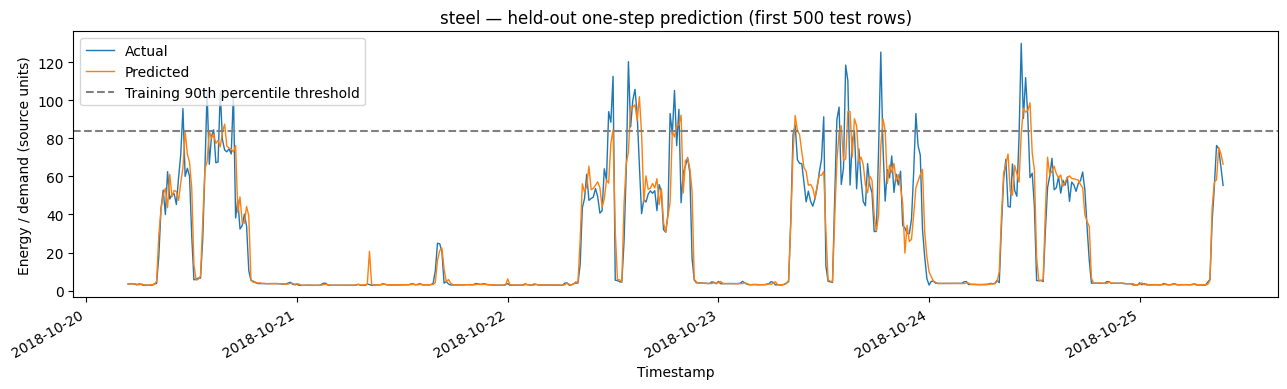

,dataset,candidate,MAE,RMSE,sMAPE_percent,selection_split
0,steel,random_forest_160,4.275960,9.149299,13.402471,validation_only
1,steel,hist_gradient_boosting,4.417077,9.106086,17.824461,validation_only
2,steel,seasonal_naive_lag96,14.981172,28.617212,43.995151,validation_only


CHAMPION: random_forest_160 TEST MAE: 3.9369 TEST PEAK F1: 0.7314
Steel target: Usage_kWh per 15-minute interval; no timestamp leakage or same-row power-factor features used.


In [7]:
steel_result,steel_candidates=run_experiment('steel',steel,15,export_features=True)
print('Steel target: Usage_kWh per 15-minute interval; no timestamp leakage or same-row power-factor features used.')

## 07 — Experiment B: Electricity Load (multiseries, per-client models)


 electricity_MT_156 


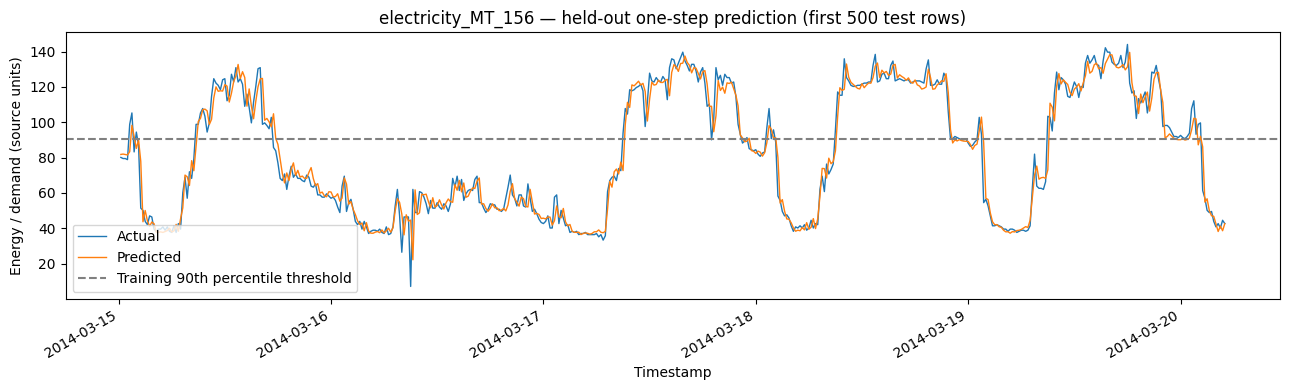

,dataset,candidate,MAE,RMSE,sMAPE_percent,selection_split
0,electricity_MT_156,hist_gradient_boosting,6.839445,9.516698,8.328538,validation_only
1,electricity_MT_156,random_forest_160,7.008620,9.839521,8.502585,validation_only
2,electricity_MT_156,seasonal_naive_lag96,24.201542,33.263937,31.101233,validation_only


CHAMPION: hist_gradient_boosting TEST MAE: 4.592 TEST PEAK F1: 0.9467

 electricity_MT_158 


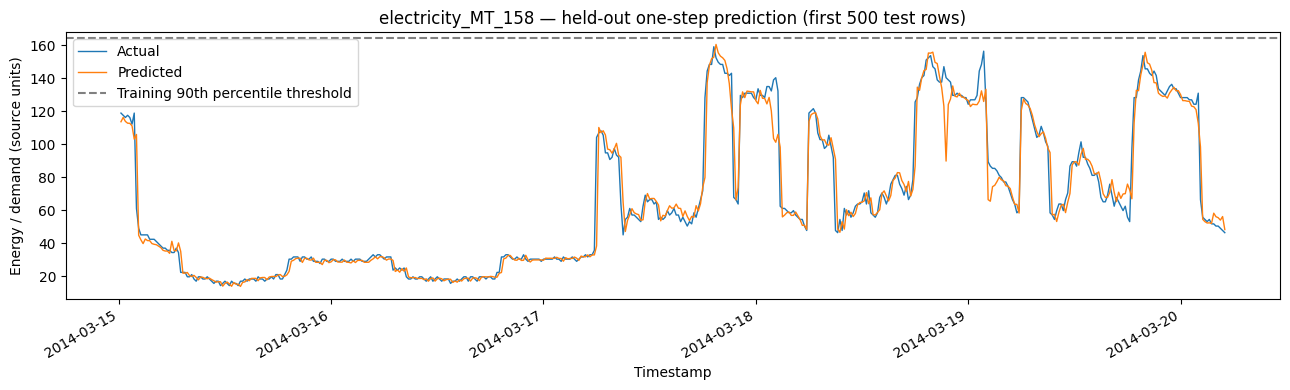

,dataset,candidate,MAE,RMSE,sMAPE_percent,selection_split
0,electricity_MT_158,hist_gradient_boosting,5.128499,10.654077,8.115939,validation_only
1,electricity_MT_158,random_forest_160,5.481916,11.309165,8.418546,validation_only
2,electricity_MT_158,seasonal_naive_lag96,30.539721,49.363942,45.880708,validation_only


CHAMPION: hist_gradient_boosting TEST MAE: 5.5181 TEST PEAK F1: 0.7405

 electricity_MT_159 


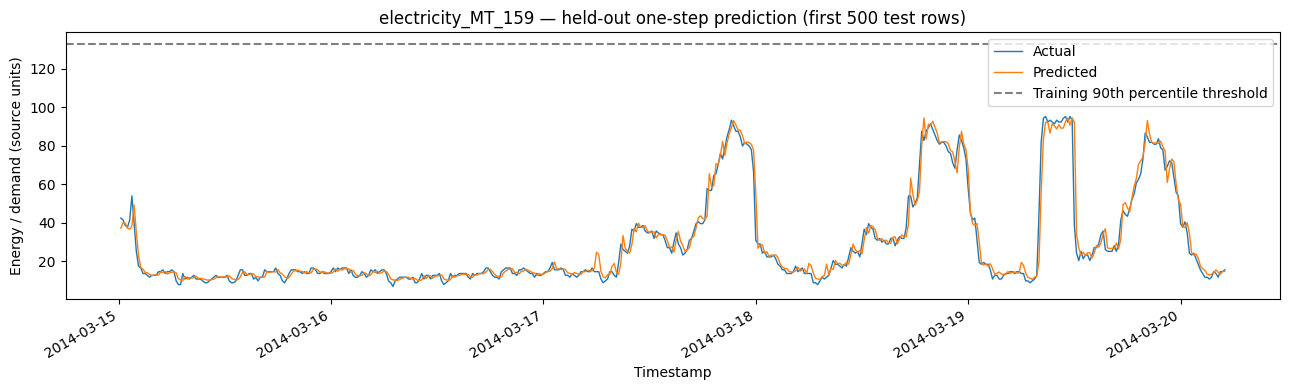

,dataset,candidate,MAE,RMSE,sMAPE_percent,selection_split
0,electricity_MT_159,hist_gradient_boosting,3.271086,6.151779,7.679813,validation_only
1,electricity_MT_159,random_forest_160,3.301113,6.155949,7.670508,validation_only
2,electricity_MT_159,seasonal_naive_lag96,25.023591,40.284625,49.836482,validation_only


CHAMPION: hist_gradient_boosting TEST MAE: 2.8897 TEST PEAK F1: 0.0

 electricity_MT_166 


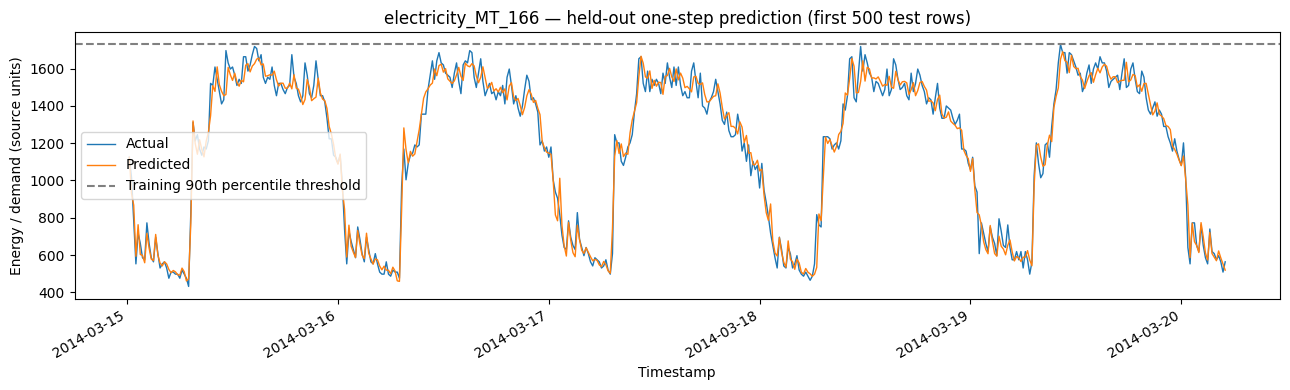

,dataset,candidate,MAE,RMSE,sMAPE_percent,selection_split
0,electricity_MT_166,random_forest_160,52.649003,76.166007,4.379189,validation_only
1,electricity_MT_166,hist_gradient_boosting,53.614776,76.972889,4.534722,validation_only
2,electricity_MT_166,seasonal_naive_lag96,93.683402,147.571046,8.201414,validation_only


CHAMPION: random_forest_160 TEST MAE: 51.6183 TEST PEAK F1: 0.3587

 electricity_MT_168 


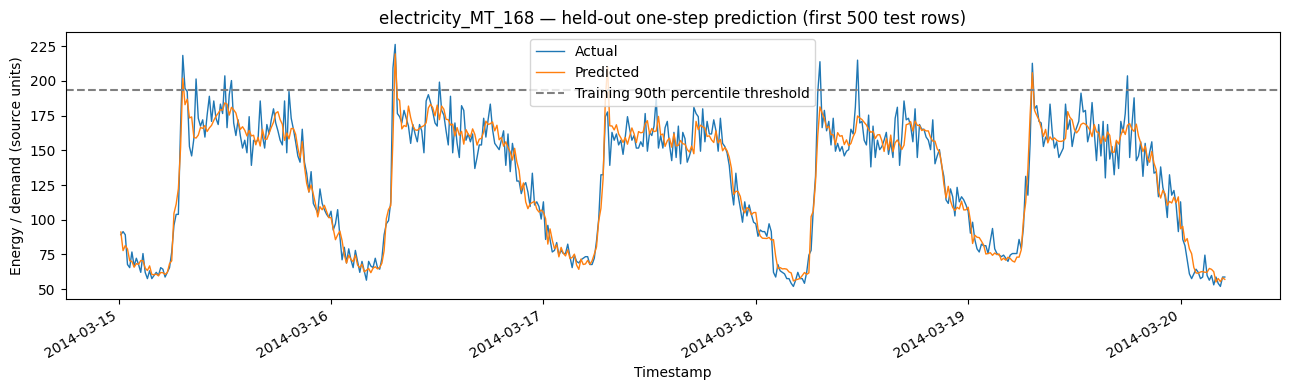

,dataset,candidate,MAE,RMSE,sMAPE_percent,selection_split
0,electricity_MT_168,random_forest_160,7.943577,11.137263,6.059333,validation_only
1,electricity_MT_168,hist_gradient_boosting,8.165929,11.311519,6.287161,validation_only
2,electricity_MT_168,seasonal_naive_lag96,11.729962,17.444814,9.137426,validation_only


CHAMPION: random_forest_160 TEST MAE: 7.9258 TEST PEAK F1: 0.0863

 electricity_MT_169 


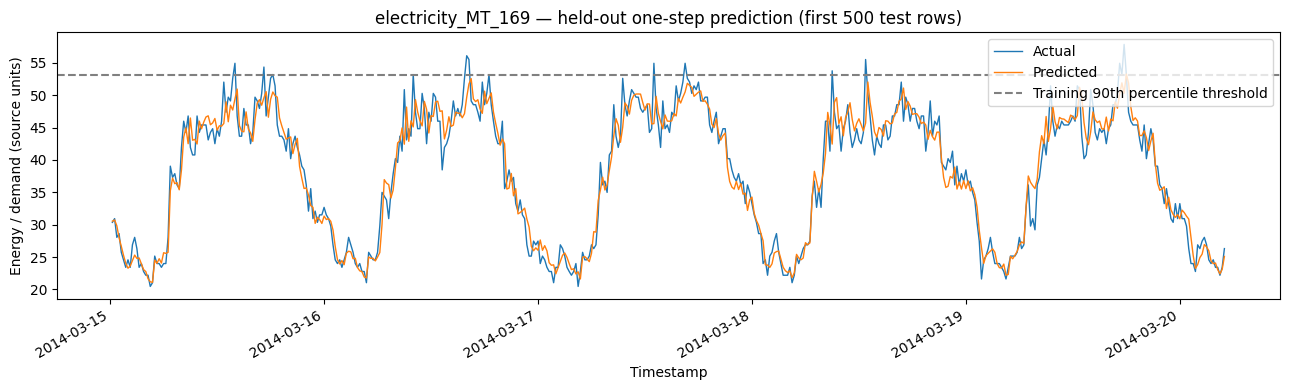

,dataset,candidate,MAE,RMSE,sMAPE_percent,selection_split
0,electricity_MT_169,random_forest_160,1.848232,2.489745,4.629727,validation_only
1,electricity_MT_169,hist_gradient_boosting,1.853405,2.492712,4.644992,validation_only
2,electricity_MT_169,seasonal_naive_lag96,2.881107,4.321363,7.060216,validation_only


CHAMPION: random_forest_160 TEST MAE: 1.916 TEST PEAK F1: 0.7528

 electricity_MT_171 


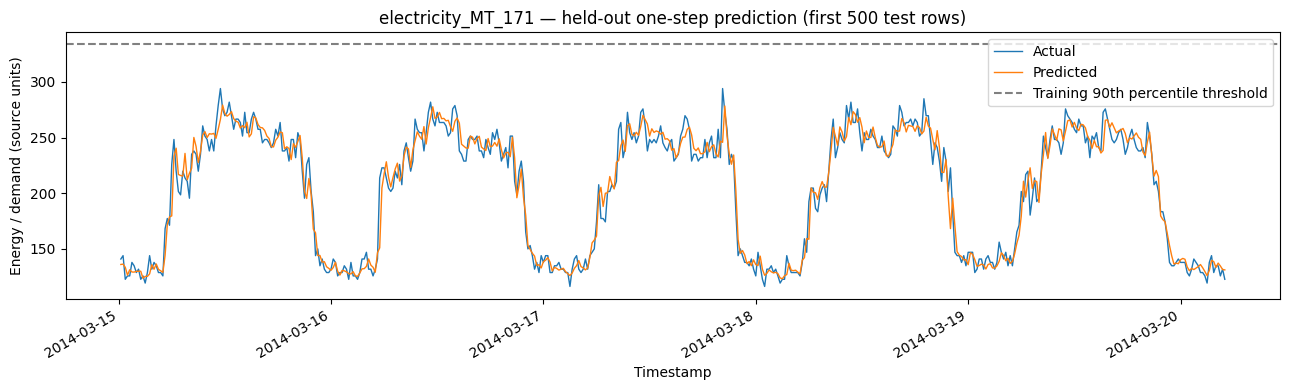

,dataset,candidate,MAE,RMSE,sMAPE_percent,selection_split
0,electricity_MT_171,hist_gradient_boosting,10.093026,13.467842,4.639126,validation_only
1,electricity_MT_171,random_forest_160,10.139685,13.579681,4.622500,validation_only
2,electricity_MT_171,seasonal_naive_lag96,17.102217,24.929074,7.689206,validation_only


CHAMPION: hist_gradient_boosting TEST MAE: 8.7884 TEST PEAK F1: 0.3795

 electricity_MT_172 


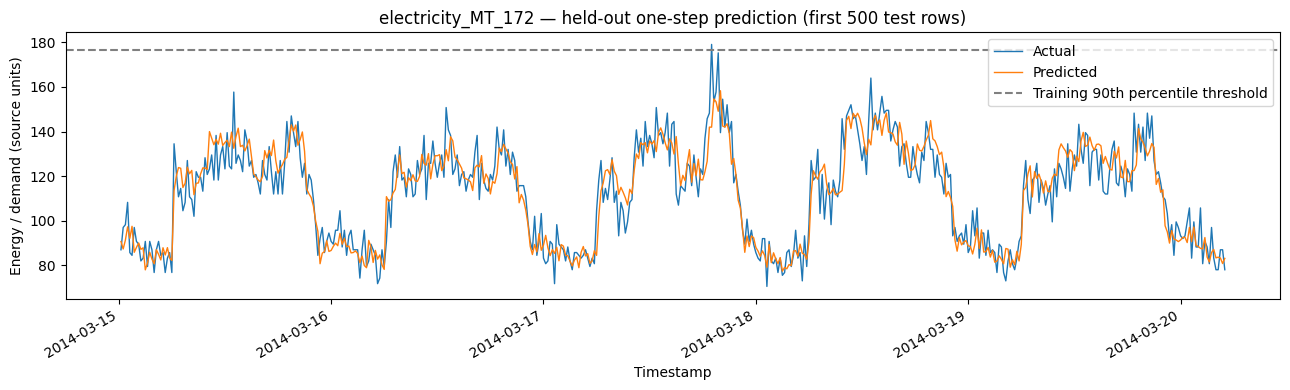

,dataset,candidate,MAE,RMSE,sMAPE_percent,selection_split
0,electricity_MT_172,hist_gradient_boosting,8.259885,11.012814,7.010662,validation_only
1,electricity_MT_172,random_forest_160,8.347154,11.138176,7.076813,validation_only
2,electricity_MT_172,seasonal_naive_lag96,13.202802,18.666464,10.781998,validation_only


CHAMPION: hist_gradient_boosting TEST MAE: 7.4591 TEST PEAK F1: 0.7544

 electricity_MT_176 


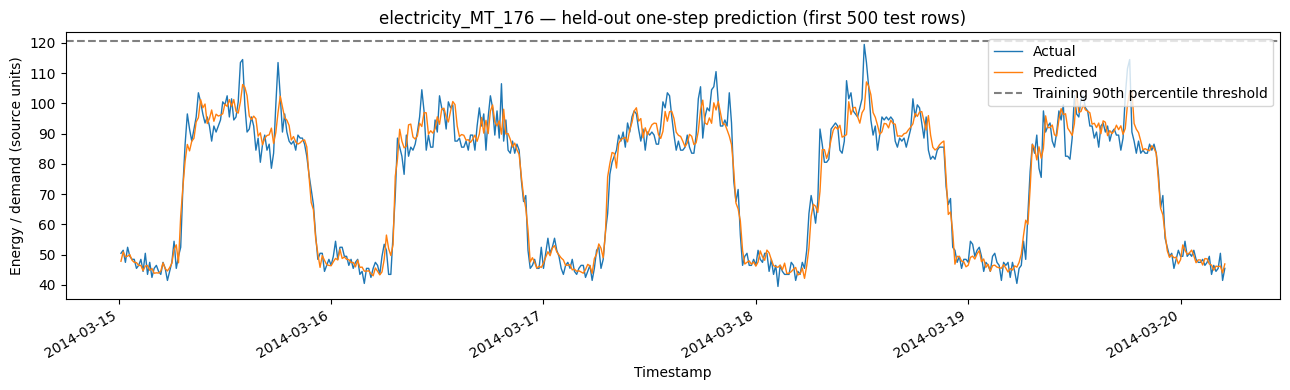

,dataset,candidate,MAE,RMSE,sMAPE_percent,selection_split
0,electricity_MT_176,random_forest_160,4.688748,6.304314,5.855830,validation_only
1,electricity_MT_176,hist_gradient_boosting,4.693169,6.256851,5.874835,validation_only
2,electricity_MT_176,seasonal_naive_lag96,7.511142,10.705231,9.267587,validation_only


CHAMPION: random_forest_160 TEST MAE: 4.1309 TEST PEAK F1: 0.7863

 electricity_MT_180 


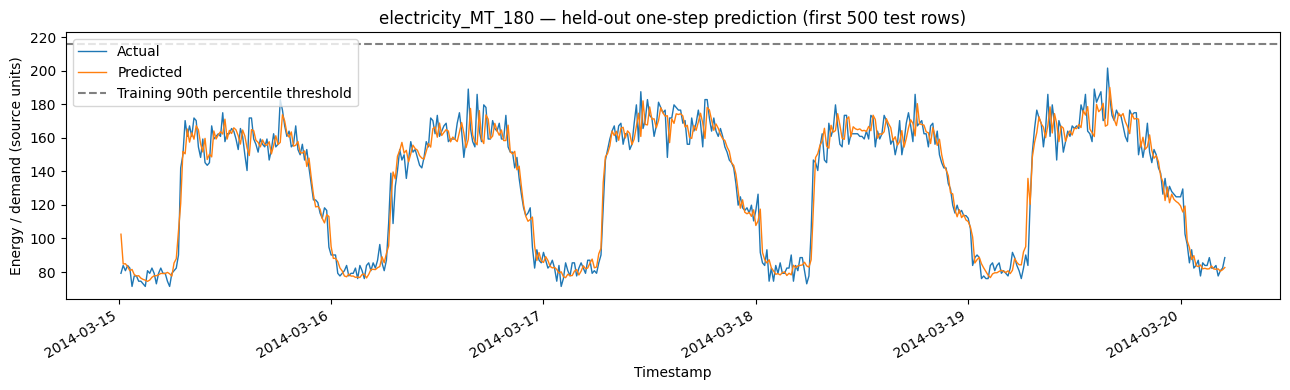

,dataset,candidate,MAE,RMSE,sMAPE_percent,selection_split
0,electricity_MT_180,hist_gradient_boosting,6.760754,9.636840,4.652489,validation_only
1,electricity_MT_180,random_forest_160,6.841754,9.704029,4.711675,validation_only
2,electricity_MT_180,seasonal_naive_lag96,17.075381,24.689216,11.539025,validation_only


CHAMPION: hist_gradient_boosting TEST MAE: 7.1417 TEST PEAK F1: 0.896

 electricity_MT_182 


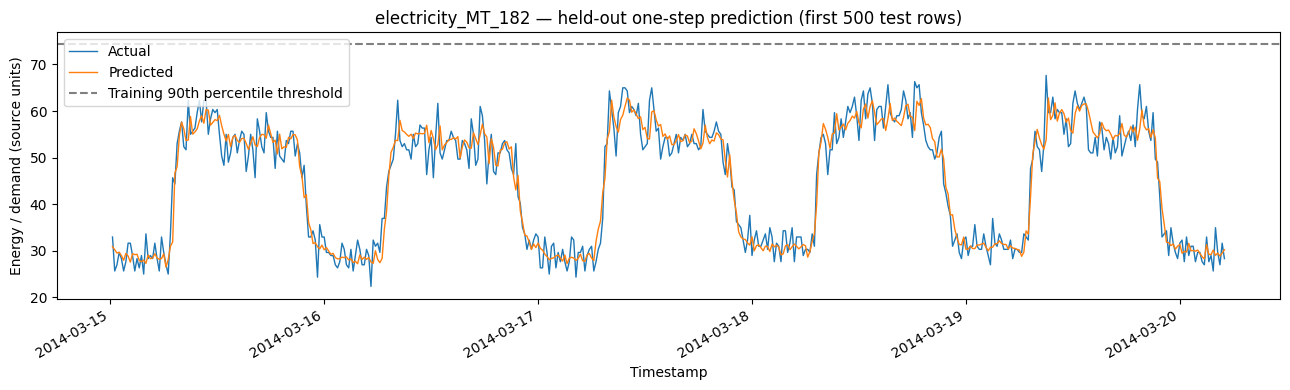

,dataset,candidate,MAE,RMSE,sMAPE_percent,selection_split
0,electricity_MT_182,hist_gradient_boosting,2.926854,3.770954,6.242448,validation_only
1,electricity_MT_182,random_forest_160,2.935911,3.783680,6.252651,validation_only
2,electricity_MT_182,seasonal_naive_lag96,4.165588,5.658504,8.728912,validation_only


CHAMPION: hist_gradient_boosting TEST MAE: 2.8292 TEST PEAK F1: 0.3136

 electricity_MT_183 


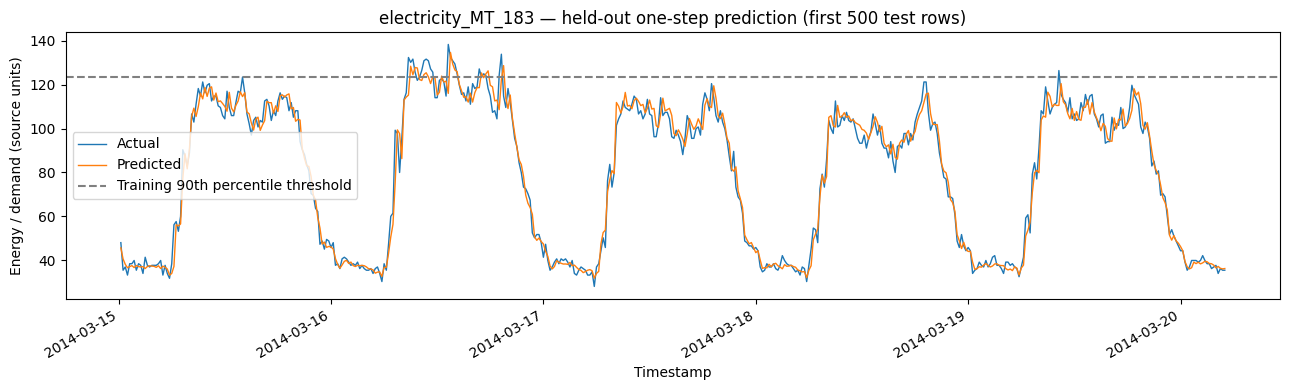

,dataset,candidate,MAE,RMSE,sMAPE_percent,selection_split
0,electricity_MT_183,random_forest_160,3.765946,5.324969,4.636711,validation_only
1,electricity_MT_183,hist_gradient_boosting,3.769306,5.284412,4.704373,validation_only
2,electricity_MT_183,seasonal_naive_lag96,7.444258,11.439478,8.799047,validation_only


CHAMPION: random_forest_160 TEST MAE: 3.7906 TEST PEAK F1: 0.6693
Clients requested: 12 successful: 12


,client,champion,MAE,RMSE,peak_f1
0,MT_156,hist_gradient_boosting,4.591979,6.511532,0.946670
1,MT_158,hist_gradient_boosting,5.518052,9.425552,0.740519
2,MT_159,hist_gradient_boosting,2.889724,5.272448,0.000000
3,MT_166,random_forest_160,51.618325,71.859113,0.358677
4,MT_168,random_forest_160,7.925802,10.718289,0.086275
5,MT_169,random_forest_160,1.916028,2.576802,0.752789
6,MT_171,hist_gradient_boosting,8.788382,12.165382,0.379487
7,MT_172,hist_gradient_boosting,7.459140,9.790797,0.754418
8,MT_176,random_forest_160,4.130948,5.618858,0.786298
9,MT_180,hist_gradient_boosting,7.141680,10.129295,0.896023


In [8]:
# Keep each client independent. Do not sum disparate customer series or present aggregate MAE as an industrial-steel result.
electricity_results=[]
for ix,client in enumerate(selected_clients,1):
    series=electricity_raw[['timestamp',client]].rename(columns={client:'value'}).copy()
    try:
        cleaned,audit=audit_series(series,client,15)
        report,_=run_experiment(f'electricity_{client}',cleaned,15,export_features=False)
        report.update({'client':client,'raw_missing_values':int(series.value.isna().sum()),'audit_irregular_intervals':audit['irregular_intervals']})
        electricity_results.append(report)
    except Exception as exc:
        electricity_results.append({'dataset':f'electricity_{client}','client':client,'status':'failed','error':str(exc)})
        print('ERROR:',client,str(exc))
print('Clients requested:',len(selected_clients),'successful:',sum('MAE' in x for x in electricity_results))
if not any('MAE' in x for x in electricity_results):raise RuntimeError('No electricity clients completed; review parser/audit')
pd.DataFrame(electricity_results).to_json(REPORT/'electricity_results.json',orient='records',indent=2)
display(pd.DataFrame(electricity_results)[['client','champion','MAE','RMSE','peak_f1']].dropna() if all(k in pd.DataFrame(electricity_results) for k in ['client','champion','MAE','RMSE','peak_f1']) else pd.DataFrame(electricity_results))

## 08 — Experiment C: Appliances Energy Prediction (auxiliary domain)


 appliances 


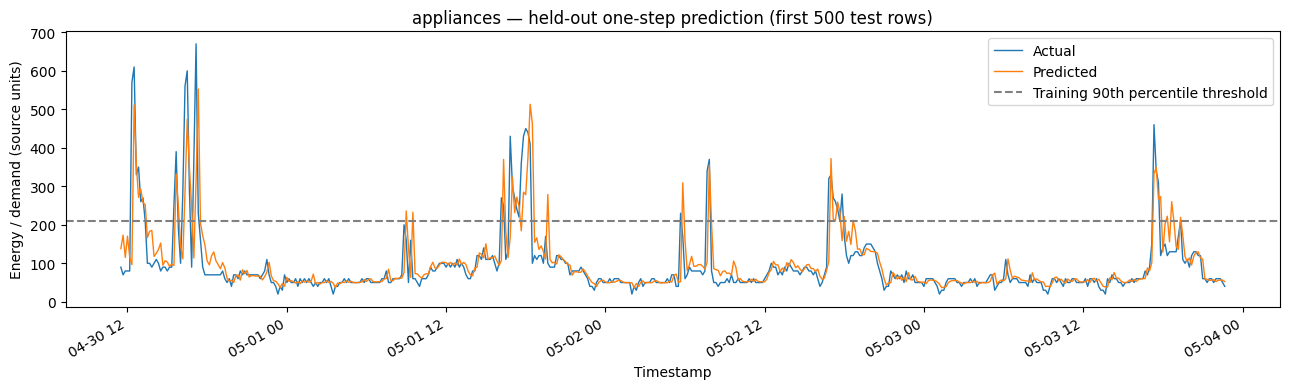

,dataset,candidate,MAE,RMSE,sMAPE_percent,selection_split
0,appliances,hist_gradient_boosting,26.959282,62.046756,21.081652,validation_only
1,appliances,random_forest_160,27.917117,61.679981,21.904696,validation_only
2,appliances,seasonal_naive_lag96,83.452138,150.642210,59.387539,validation_only


CHAMPION: hist_gradient_boosting TEST MAE: 25.3261 TEST PEAK F1: 0.7117
Caveat: Appliances measurements are residential, not industrial; one-step forecasting only.


In [9]:
appliances_result,appliances_candidates=run_experiment('appliances',appliances,10,export_features=True)
print('Caveat: Appliances measurements are residential, not industrial; one-step forecasting only.')

## 09 — Robustness audit, naive benchmark, and interpretability notes

In [10]:
results=[steel_result,*[r for r in electricity_results if 'MAE' in r],appliances_result]
summary=pd.DataFrame(results)
summary.to_csv(REPORT/'all_experiment_metrics.csv',index=False)
cols=['dataset','champion','train_n','validation_n','test_n','MAE','RMSE','sMAPE_percent','peak_precision','peak_recall','peak_f1']
display(summary[cols])
# Units and scale differ across datasets: never rank cross-dataset MAE as a single leaderboard.
for name, table in [('steel',steel_candidates),('appliances',appliances_candidates)]:
    naive=table[table.candidate=='seasonal_naive_lag96'].iloc[0]
    champ=table.iloc[0]
    print(f'{name}: val naive MAE={naive.MAE:.4f}; selected candidate {champ.candidate} val MAE={champ.MAE:.4f}')
print('WARNING: lag_96 = previous day for 15-minute data, but previous 16 hours for 10-minute Appliances. See final limitations; candidate name is technical, not a valid daily seasonal baseline for Appliances.')
print('Electricity client subset chosen by valid fraction/nonzero fraction; not a full 370-client benchmark.')

,dataset,champion,train_n,validation_n,test_n,MAE,RMSE,sMAPE_percent,peak_precision,peak_recall,peak_f1
0,steel,random_forest_160,20966,6989,6989,3.936867,8.371012,12.321487,0.707657,0.756824,0.731415
1,electricity_MT_156,hist_gradient_boosting,84096,28032,28032,4.591979,6.511532,5.773260,0.956176,0.937351,0.946670
2,electricity_MT_158,hist_gradient_boosting,84096,28032,28032,5.518052,9.425552,7.324552,0.789362,0.697368,0.740519
3,electricity_MT_159,hist_gradient_boosting,84096,28032,28032,2.889724,5.272448,9.953049,0.000000,0.000000,0.000000
4,electricity_MT_166,random_forest_160,84096,28032,28032,51.618325,71.859113,4.229701,0.588571,0.257930,0.358677
5,electricity_MT_168,random_forest_160,84096,28032,28032,7.925802,10.718289,6.142010,0.550000,0.046809,0.086275
6,electricity_MT_169,random_forest_160,84096,28032,28032,1.916028,2.576802,4.688019,0.818253,0.697024,0.752789
7,electricity_MT_171,hist_gradient_boosting,84096,28032,28032,8.788382,12.165382,3.962633,0.698113,0.260563,0.379487
8,electricity_MT_172,hist_gradient_boosting,84096,28032,28032,7.459140,9.790797,6.412782,0.865734,0.668467,0.754418
9,electricity_MT_176,random_forest_160,84096,28032,28032,4.130948,5.618858,4.997161,0.798094,0.774846,0.786298


steel: val naive MAE=14.9812; selected candidate random_forest_160 val MAE=4.2760
appliances: val naive MAE=83.4521; selected candidate hist_gradient_boosting val MAE=26.9593
Electricity client subset chosen by valid fraction/nonzero fraction; not a full 370-client benchmark.


## 10 — Model artifact round-trip and inference examples

In [11]:
# Confirm every saved model loads from disk, preserving expected feature names.
manifest=[]
for model_file in sorted(MODELS.glob('*_champion.joblib')):
    model=joblib.load(model_file)
    assert model['feature_columns']
    manifest.append({'file':model_file.name,'bytes':model_file.stat().st_size,'dataset':model['dataset'],'champion':model['champion'],'n_features':len(model['feature_columns']),'peak_cutoff':model['peak_cutoff']})
manifest_df=pd.DataFrame(manifest);display(manifest_df)
manifest_df.to_csv(REPORT/'model_manifest.csv',index=False)
assert len(manifest)>=3,'Expect Steel + Appliances + at least one Electricity model'
print('Model artifact roundtrip: PASS (deserialization and schema verified)')

,file,bytes,dataset,champion,n_features,peak_cutoff
0,appliances_champion.joblib,301880,appliances,hist_gradient_boosting,21,210.000000
1,electricity_MT_156_champion.joblib,507325,electricity_MT_156,hist_gradient_boosting,21,90.673737
2,electricity_MT_158_champion.joblib,501083,electricity_MT_158,hist_gradient_boosting,21,164.545456
3,electricity_MT_159_champion.joblib,501272,electricity_MT_159,hist_gradient_boosting,21,132.519150
4,electricity_MT_166_champion.joblib,442651632,electricity_MT_166,random_forest_160,21,1729.230713
5,electricity_MT_168_champion.joblib,452551630,electricity_MT_168,random_forest_160,21,193.521439
6,electricity_MT_169_champion.joblib,451925953,electricity_MT_169,random_forest_160,21,53.181557
7,electricity_MT_171_champion.joblib,497080,electricity_MT_171,hist_gradient_boosting,21,333.625366
8,electricity_MT_172_champion.joblib,502364,electricity_MT_172,hist_gradient_boosting,21,176.537979
9,electricity_MT_176_champion.joblib,437055361,electricity_MT_176,random_forest_160,21,120.467659


Model artifact roundtrip: PASS (deserialization and schema verified)


## 11 — Scientific limitation and claim boundaries

In [12]:
limitations={
 'task':'one-step energy value forecasting and threshold-based peak flagging; NOT actual failure detection',
 'selection':'champion chosen solely by validation MAE, test read after selection',
 'splits':'chronological within each series; no shuffle, but temporal autocorrelation is expected',
 'leakage':'lag and rolling features use previous observations only; timestamps must be available at forecast time',
 'baselines':'lag_96 means prior day at 15min cadence, but 16 hours earlier for 10min Appliances',
 'peak_definition':'90th percentile of training targets, applied unchanged to future validation/test; peak event is derived, not independently labeled',
 'electricity':'subset selected by completeness; 370 clients not fully benchmarked with default setting',
 'dataset_domains':'Steel industrial, Electricity commercial/consumer, Appliances residential; not interchangeable',
 'operational':'No cost optimization, demand-control actuation, tariff inference, grid dispatch, future exogenous forecasts, or live IoT sensor connectivity',
 'external_generalization':'No external deployment evidence or confidence intervals; distribution shifts possible',
 'quality':'Missing and duplicate timestamps reported; rows with invalid prior context excluded, not silently filled from future information',
}
(REPORT/'claim_boundaries.json').write_text(json.dumps(limitations,indent=2),encoding='utf-8')
print(json.dumps(limitations,indent=2))

{
  "task": "one-step energy value forecasting and threshold-based peak flagging; NOT actual failure detection",
  "selection": "champion chosen solely by validation MAE, test read after selection",
  "splits": "chronological within each series; no shuffle, but temporal autocorrelation is expected",
  "leakage": "lag and rolling features use previous observations only; timestamps must be available at forecast time",
  "baselines": "lag_96 means prior day at 15min cadence, but 16 hours earlier for 10min Appliances",
  "peak_definition": "90th percentile of training targets, applied unchanged to future validation/test; peak event is derived, not independently labeled",
  "electricity": "subset selected by completeness; 370 clients not fully benchmarked with default setting",
  "dataset_domains": "Steel industrial, Electricity commercial/consumer, Appliances residential; not interchangeable",
  "operational": "No cost optimization, demand-control actuation, tariff inference, grid dispatch

## 12 — Reproducibility checks and research gate

In [13]:
gate={
 'input_found':INPUT_ROOT.is_dir(),
 'dataset_inventory':{'steel':STEEL_PATH.is_file(),'electricity':ELEC_PATH.is_file(),'appliances':APP_PATH.is_file()},
 'primary_metrics_exist':(REPORT/'steel_heldout_metrics.json').is_file(),
 'secondary_metrics_exist':(REPORT/'electricity_results.json').is_file(),
 'auxiliary_metrics_exist':(REPORT/'appliances_heldout_metrics.json').is_file(),
 'models_exported':len(list(MODELS.glob('*_champion.joblib'))),
 'peak_cutoffs_train_only':True,
 'chronological_splits':True,
 'validation_only_champion_selection':True,
 'domain_separation':True,
 'provenance_written':(REPORT/'source_provenance.csv').is_file(),
 'limits_documented':(REPORT/'claim_boundaries.json').is_file(),
}
gate['status']='PASS_REPRODUCIBILITY' if all([gate['input_found'],*gate['dataset_inventory'].values(),gate['primary_metrics_exist'],gate['secondary_metrics_exist'],gate['auxiliary_metrics_exist'],gate['models_exported']>=3,gate['provenance_written'],gate['limits_documented']]) else 'FAIL'
(REPORT/'research_gate.json').write_text(json.dumps(gate,indent=2),encoding='utf-8')
print(json.dumps(gate,indent=2))
assert gate['status']=='PASS_REPRODUCIBILITY','Research artifact gate failed'

{
  "input_found": true,
  "dataset_inventory": {
    "steel": true,
    "electricity": true,
    "appliances": true
  },
  "primary_metrics_exist": true,
  "secondary_metrics_exist": true,
  "auxiliary_metrics_exist": true,
  "models_exported": 14,
  "peak_cutoffs_train_only": true,
  "chronological_splits": true,
  "validation_only_champion_selection": true,
  "domain_separation": true,
  "provenance_written": true,
  "limits_documented": true,
  "status": "PASS_REPRODUCIBILITY"
}


## 13 — Package complete research outputs (no original datasets)

In [14]:
readme=f"""# EnergyPeak Predictor — Day 27 / 100

Inputs: {INPUT_ROOT}

Three independent forecasting domains: Steel Industry (primary), Electricity Load (multi-client secondary), Appliances (residential auxiliary).

Split: chronological 60/20/20. Select models by validation MAE; evaluate untouched test. Peak threshold: original training-target 90th percentile.

Outputs: models/, reports/, plots/, optionally features/. Raw datasets are NOT redistributed.

Sources:
- UCI Steel: https://archive.ics.uci.edu/dataset/851/steel+industry+energy+consumption
- UCI Electricity: https://archive.ics.uci.edu/dataset/321/electricityloaddiagrams20112014
- UCI Appliances: https://archive.ics.uci.edu/dataset/374/appliances+energy+prediction

Limitations are enumerated in reports/claim_boundaries.json. This is a research prototype, NOT an operational grid controller.
"""
(OUT/'README.md').write_text(readme,encoding='utf-8')
archive=Path('/kaggle/working/EnergyPeak_Day27_FINAL_Artifacts.zip')
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6,allowZip64=True) as z:
    for p in sorted(OUT.rglob('*')):
        if p.is_file():
            if not CFG['zip_include_features'] and 'features' in p.relative_to(OUT).parts:continue
            z.write(p,arcname=str(Path('energypeak_day27')/p.relative_to(OUT)))
with zipfile.ZipFile(archive) as z:
    bad=z.testzip()
    if bad:raise RuntimeError(f'ZIP CRC FAILED: {bad}')
    print('FINAL ZIP CRC PASS:',archive,'files:',len(z.namelist()),'MiB:',round(archive.stat().st_size/1024**2,2))
print('DONE — actual results are in reports/, not fabricated or pre-filled.')

FINAL ZIP CRC PASS: /kaggle/working/EnergyPeak_Day27_FINAL_Artifacts.zip files: 80 MiB: 633.79
DONE — actual results are in reports/, not fabricated or pre-filled.
